# AwA2 — probing por cabeza sobre atributos (bloque 4, token CLS)

## 0. Configuración

In [1]:
# ======================================================================
MODELS = {"unconstrained": "vit-15-AwA2", "constrained": "vit-15-constrained-AwA2", "constrained_rank": "vit-15-constrained_rank-AwA2"}
BLOCK_IDX = 4             # 1-indexed, como en ablation.ipynb / head_specialization.ipynb
TOKEN = "cls"             # "cls" | "mean_patches" (promedio de la salida de la cabeza sobre los 64 parches)
N_FOLDS = 5
R2_THRESHOLD = 0.3        # "atributo bien predicho" por una cabeza (se reporta también un barrido)
BALACC_THRESHOLD = 0.75
SEED = 0

# Filtro de ruido: solo atributos con correlato visual directo en una imagen estática
# (taxonomía de categorías de Lampert et al., AwA2). Se excluyen comportamiento/locomoción,
# actividad, dieta, estrategia de forrajeo, carácter/temperamento y geografía (newworld/oldworld),
# que no son algo que un probe sobre una imagen pueda ver, solo inferir por correlación con la especie.
VISUAL_ATTRS = {
    # color (8)
    "black", "white", "blue", "brown", "gray", "orange", "red", "yellow",
    # textura (6)
    "patches", "spots", "stripes", "furry", "hairless", "toughskin",
    # forma (4)
    "big", "small", "bulbous", "lean",
    # partes del cuerpo (15)
    "flippers", "hands", "hooves", "pads", "paws", "longleg", "longneck", "tail",
    "chewteeth", "meatteeth", "buckteeth", "strainteeth", "horns", "claws", "tusks",
    # hábitat / escenario visible en la foto (14, sin newworld/oldworld)
    "arctic", "coastal", "desert", "bush", "plains", "forest", "fields", "jungle",
    "mountains", "ocean", "ground", "water", "tree", "cave",
}
# ======================================================================

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression, RidgeCV
from sklearn.metrics import balanced_accuracy_score, r2_score
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

project_root = Path.cwd().resolve().parents[1]
sys.path.append(str(project_root))

from modules.datasets import AwA2Dataset
from modules.model import ViTForClassfication

torch.manual_seed(SEED)
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

EXPERIMENTS_DIR = project_root / "experimentation" / "experiments"
OUTPUT_DIR = EXPERIMENTS_DIR / "25092026_awa2_probing"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RUN_TAG = f"block{BLOCK_IDX}_{TOKEN}_visual"


def save_fig(fig, stem):
    fig.savefig(OUTPUT_DIR / f"{stem}_{RUN_TAG}.png", dpi=150, bbox_inches="tight")

## 1. Datos y modelos

In [2]:
dataset = AwA2Dataset(image_size=32, root=str(project_root / "data" / "awa2"))
_, testloader, classes = dataset.get_loaders(batch_size=256)
attr_names = list(dataset.attribute_names)

labels = dataset.testset.labels.numpy()
Y_cont = dataset.attributes_continuous[labels].numpy()   # (N, 85) en [0, 1]
Y_bin = dataset.attributes_binary[labels].numpy().astype(int)

# Filtro de ruido no-visual (ver VISUAL_ATTRS en la config): de acá en adelante todo el notebook
# trabaja solo sobre atributos con correlato visual directo.
visual_mask = np.array([name in VISUAL_ATTRS for name in attr_names])
dropped = [name for name in attr_names if name not in VISUAL_ATTRS]
attr_names = [name for name in attr_names if name in VISUAL_ATTRS]
Y_cont = Y_cont[:, visual_mask]
Y_bin = Y_bin[:, visual_mask]
n_attr = len(attr_names)
print(f"atributos: {n_attr} visuales de {len(visual_mask)} totales ({len(dropped)} descartados)")
print(f"test: {len(labels)} imágenes, {len(classes)} clases, {n_attr} atributos")


def load_model(name):
    exp_dir = EXPERIMENTS_DIR / name
    config = json.loads((exp_dir / "config.json").read_text())
    metrics = json.loads((exp_dir / "metrics.json").read_text())
    assert not config["use_faster_attention"], "se asume block.attention.heads como submódulos separados"
    model = ViTForClassfication(config)
    model.load_state_dict(torch.load(exp_dir / "model_final.pt", map_location="cpu"))
    return model.to(device).eval(), config, metrics


models = {key: load_model(name) for key, name in MODELS.items()}
n_heads = models["unconstrained"][1]["num_attention_heads"]
block_idx0 = BLOCK_IDX - 1
head_labels = [f"head {h + 1}" for h in range(n_heads)]

atributos: 47 visuales de 85 totales (38 descartados)
test: 7468 imágenes, 50 clases, 47 atributos


## 2. Extracción de la salida de cada cabeza

In [3]:
@torch.no_grad()
def extract_head_outputs(model):
    captured = {}
    heads = model.encoder.blocks[block_idx0].attention.heads
    hooks = [head.register_forward_hook(lambda _m, _i, out, h=h: captured.__setitem__(h, out[0]))
             for h, head in enumerate(heads)]
    feats, preds = [], []
    try:
        for images, _, _ in testloader:
            logits, _ = model(images.to(device))
            per_head = torch.stack([captured[h] for h in range(n_heads)], dim=1)   # (B, H, T, d)
            per_head = per_head[:, :, 0] if TOKEN == "cls" else per_head[:, :, 1:].mean(dim=2)
            feats.append(per_head.cpu())
            preds.append(logits.argmax(-1).cpu())
    finally:
        for hook in hooks:
            hook.remove()
    return torch.cat(feats).numpy(), torch.cat(preds).numpy()


head_feats = {}
for key, (model, _, metrics) in models.items():
    head_feats[key], preds = extract_head_outputs(model)
    acc = (preds == labels).mean()
    print(f"{key:>13}: feats {head_feats[key].shape}, accuracy recomputada {acc:.4f} "
          f"(metrics.json: {metrics['accuracy']:.4f})")

unconstrained: feats (7468, 4, 12), accuracy recomputada 0.2971 (metrics.json: 0.2971)


  constrained: feats (7468, 4, 12), accuracy recomputada 0.2879 (metrics.json: 0.2879)


constrained_rank: feats (7468, 4, 12), accuracy recomputada 0.2973 (metrics.json: 0.2973)


## 3. Probing lineal por cabeza × atributo

In [4]:
folds_image = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(labels, labels))
folds_class = list(GroupKFold(N_FOLDS).split(labels, labels, groups=labels))   # clases no vistas


def probe_r2(X, Y, folds):
    """R² out-of-fold por atributo (Ridge multi-salida, alpha elegido por atributo dentro de cada fold)."""
    pred = np.zeros_like(Y)
    for tr, te in folds:
        probe = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-3, 3, 13), alpha_per_target=True))
        pred[te] = probe.fit(X[tr], Y[tr]).predict(X[te])
    return r2_score(Y, pred, multioutput="raw_values")


def probe_balacc(X, Yb, folds):
    """Balanced accuracy out-of-fold por atributo binarizado (logística con class_weight balanceado)."""
    scores = np.full(Yb.shape[1], np.nan)
    for a in range(Yb.shape[1]):
        y = Yb[:, a]
        if y.min() == y.max():
            continue
        pred = np.zeros_like(y)
        for tr, te in folds:
            probe = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))
            pred[te] = probe.fit(X[tr], y[tr]).predict(X[te])
        scores[a] = balanced_accuracy_score(y, pred)
    return scores


r2, r2_unseen, balacc = {}, {}, {}
r2_block, r2_block_unseen, balacc_block = {}, {}, {}
for key, feats in head_feats.items():
    r2[key] = np.stack([probe_r2(feats[:, h], Y_cont, folds_image) for h in range(n_heads)])          # (H, 85)
    r2_unseen[key] = np.stack([probe_r2(feats[:, h], Y_cont, folds_class) for h in range(n_heads)])
    balacc[key] = np.stack([probe_balacc(feats[:, h], Y_bin, folds_image) for h in range(n_heads)])
    # Probe sobre las 4 cabezas concatenadas (48-d), por atributo: lo decodificable del bloque cuando las
    # cabezas se usan juntas. Mismas métricas y mismos folds que el probe por cabeza.
    X_block = feats.reshape(len(feats), -1)
    r2_block[key] = probe_r2(X_block, Y_cont, folds_image)                       # (n_attr,)
    r2_block_unseen[key] = probe_r2(X_block, Y_cont, folds_class)
    balacc_block[key] = probe_balacc(X_block, Y_bin, folds_image)
    print(f"{key:>13}: R² medio {r2[key].mean():.3f} | clases no vistas {r2_unseen[key].mean():.3f} | "
          f"bal.acc media {np.nanmean(balacc[key]):.3f}")
    print(f"{'':>13}  4 cabezas (48-d): R² {r2_block[key].mean():.3f} | clases no vistas "
          f"{r2_block_unseen[key].mean():.3f} | bal.acc {np.nanmean(balacc_block[key]):.3f}")

for key in MODELS:
    pd.DataFrame(r2[key], index=head_labels, columns=attr_names).to_csv(OUTPUT_DIR / f"r2_{key}_{RUN_TAG}.csv")
    pd.DataFrame(r2_unseen[key], index=head_labels, columns=attr_names).to_csv(OUTPUT_DIR / f"r2_unseen_classes_{key}_{RUN_TAG}.csv")
    pd.DataFrame(balacc[key], index=head_labels, columns=attr_names).to_csv(OUTPUT_DIR / f"balacc_{key}_{RUN_TAG}.csv")
    pd.DataFrame({"R2": r2_block[key], "R2_unseen_classes": r2_block_unseen[key], "balacc": balacc_block[key]},
                 index=attr_names).to_csv(OUTPUT_DIR / f"block_concat_{key}_{RUN_TAG}.csv")

unconstrained: R² medio 0.076 | clases no vistas -0.022 | bal.acc media 0.630
               4 cabezas (48-d): R² 0.161 | clases no vistas 0.007 | bal.acc 0.695


  constrained: R² medio 0.044 | clases no vistas -0.048 | bal.acc media 0.607
               4 cabezas (48-d): R² 0.123 | clases no vistas -0.035 | bal.acc 0.677


constrained_rank: R² medio 0.047 | clases no vistas -0.039 | bal.acc media 0.604
               4 cabezas (48-d): R² 0.116 | clases no vistas -0.022 | bal.acc 0.664


## 4. Heatmaps cabeza × atributo

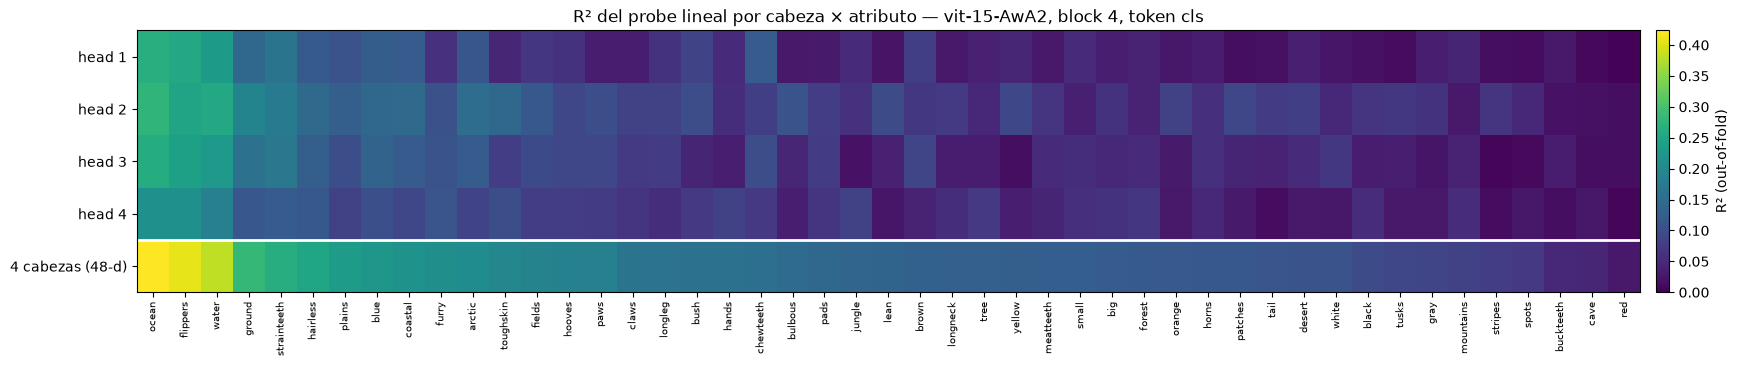

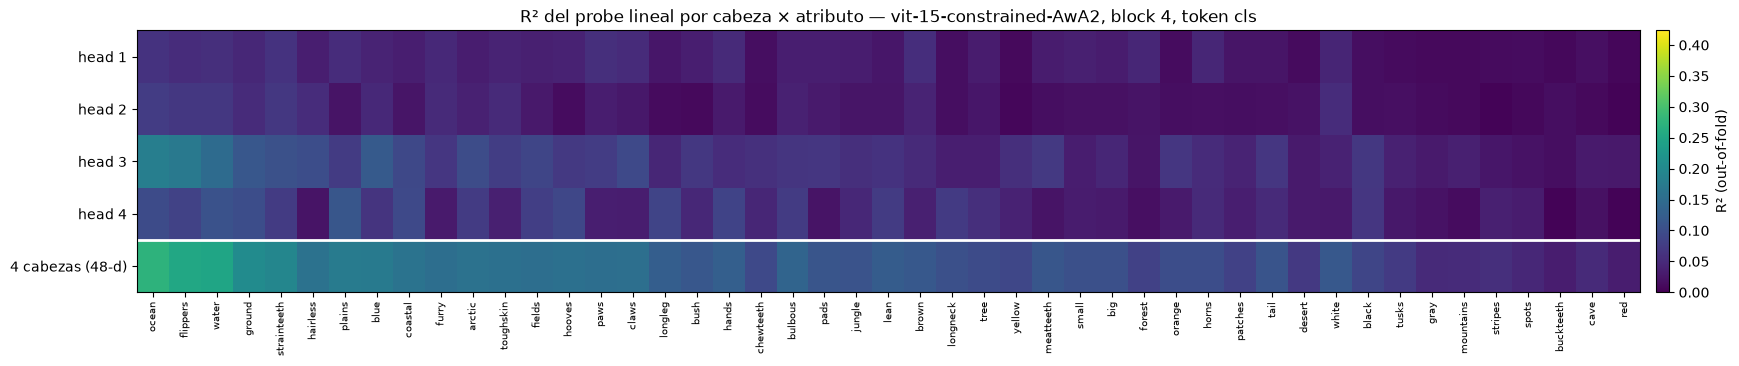

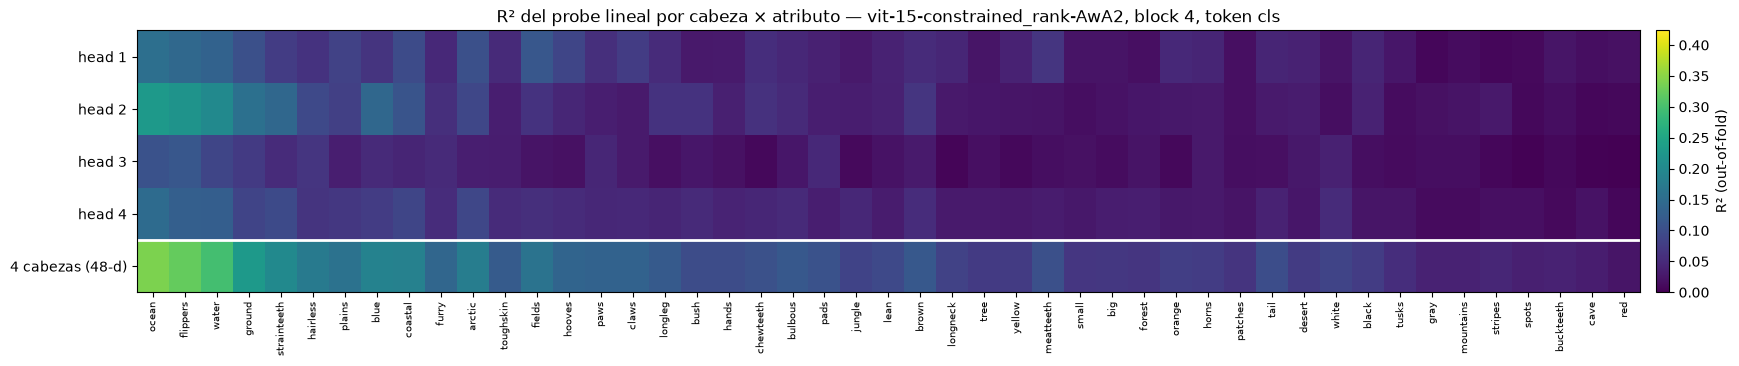

In [5]:
attr_order = np.argsort(-r2_block["unconstrained"])
vmax = max(max(r2[k].max(), r2_block[k].max()) for k in MODELS)

for key in MODELS:
    fig, ax = plt.subplots(figsize=(20, 3.4))
    scores = np.vstack([r2[key], r2_block[key][None]])       # última fila: 4 cabezas concatenadas
    im = ax.imshow(np.clip(scores[:, attr_order], 0, None), cmap="viridis", vmin=0, vmax=vmax, aspect="auto")
    ax.axhline(n_heads - 0.5, color="w", lw=2)
    ax.set_yticks(range(n_heads + 1)); ax.set_yticklabels(head_labels + ["4 cabezas (48-d)"])
    ax.set_xticks(range(n_attr)); ax.set_xticklabels([attr_names[i] for i in attr_order], rotation=90, fontsize=7)
    ax.set_title(f"R² del probe lineal por cabeza × atributo — {MODELS[key]}, block {BLOCK_IDX}, token {TOKEN}")
    fig.colorbar(im, ax=ax, label="R² (out-of-fold)", fraction=0.02, pad=0.01)
    save_fig(fig, f"r2_heatmap_{key}")
    plt.show()

## 5. Métricas de especialización

In [6]:
from modules.similarity import offdiag_mean, pairwise_similarity_matrix


def jaccard_matrix(masks):
    H = masks.shape[0]
    M = np.eye(H)
    for i in range(H):
        for j in range(i + 1, H):
            union = (masks[i] | masks[j]).sum()
            M[i, j] = M[j, i] = (masks[i] & masks[j]).sum() / union if union else np.nan
    return M


def offdiag_mean(M):
    iu = np.triu_indices(M.shape[0], k=1)
    return float(np.nanmean(M[iu]))


def specialization_metrics(scores, threshold):
    """scores: (H, n_attr), mayor = mejor. Devuelve dict de métricas escalares."""
    pos = np.clip(np.nan_to_num(scores, nan=0.0), 0, None)
    good = scores > threshold                       # (H, n_attr)
    covered = good.any(axis=0)
    p = pos / np.where(pos.sum(0) > 0, pos.sum(0), 1)
    entropy = -(p * np.log(np.where(p > 0, p, 1))).sum(0) / np.log(scores.shape[0])
    return {
        "cobertura (nº atributos)": int(covered.sum()),
        "cabezas por atributo cubierto": float(good[:, covered].sum(0).mean()) if covered.any() else np.nan,
        "Jaccard medio entre cabezas": offdiag_mean(jaccard_matrix(good)),
        "entropía normalizada entre cabezas": float(entropy[covered].mean()) if covered.any() else np.nan,
        **{f"nº atributos > τ, {head_labels[h]}": int(good[h].sum()) for h in range(scores.shape[0])},
    }


cosine = {k: pairwise_similarity_matrix(np.clip(r2[k], 0, None), "cosine") for k in MODELS}
pearson = {k: pairwise_similarity_matrix(np.clip(r2[k], 0, None), "pearson") for k in MODELS}

rows = {}
for key, (_, _, metrics) in models.items():
    rows[key] = {
        "accuracy (test)": metrics["accuracy"],
        "R² medio (cabeza × atributo)": float(r2[key].mean()),
        "R² máx. por atributo, media": float(r2[key].max(0).mean()),
        "R² bloque completo (48-d), media": float(r2_block[key].mean()),
        "ganancia concat − mejor cabeza (R², media)": float((r2_block[key] - r2[key].max(0)).mean()),
        "atributos donde concat > mejor cabeza": int((r2_block[key] > r2[key].max(0)).sum()),
        "R² medio, clases no vistas": float(r2_unseen[key].mean()),
        "R² bloque completo, clases no vistas": float(r2_block_unseen[key].mean()),
        "bal.acc media (binarizado)": float(np.nanmean(balacc[key])),
        "bal.acc media bloque completo (48-d)": float(np.nanmean(balacc_block[key])),
        f"cobertura bal.acc > {BALACC_THRESHOLD}": int((balacc[key] > BALACC_THRESHOLD).any(0).sum()),
        f"cobertura bal.acc > {BALACC_THRESHOLD}, bloque completo": int((balacc_block[key] > BALACC_THRESHOLD).sum()),
        "coseno medio entre vectores de R²": offdiag_mean(cosine[key]),
        "Pearson medio entre vectores de R²": offdiag_mean(pearson[key]),
        **{f"[τ={R2_THRESHOLD}] {m}": v for m, v in specialization_metrics(r2[key], R2_THRESHOLD).items()},
        **{f"[clases no vistas, τ={R2_THRESHOLD}] {m}": v
           for m, v in specialization_metrics(r2_unseen[key], R2_THRESHOLD).items() if not m.startswith("nº")},
    }

summary = pd.DataFrame(rows)
summary["Δ (constrained − unconstrained)"] = summary["constrained"] - summary["unconstrained"]
summary["Δ (constrained_rank − constrained)"] = summary["constrained_rank"] - summary["constrained"]
summary.to_csv(OUTPUT_DIR / f"summary_{RUN_TAG}.csv")
summary.round(3)

/var/folders/sx/_3f9ftxx24q3hbz_25d1xrjh0000gn/T/ipykernel_11234/2787426557.py:16: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(M[iu]))


,unconstrained,constrained,constrained_rank,Δ (constrained − unconstrained),Δ (constrained_rank − constrained)
accuracy (test),0.297,0.288,0.297,-0.009,0.009
R² medio (cabeza × atributo),0.076,0.044,0.047,-0.031,0.002
"R² máx. por atributo, media",0.100,0.072,0.067,-0.028,-0.005
"R² bloque completo (48-d), media",0.161,0.123,0.116,-0.038,-0.007
"ganancia concat − mejor cabeza (R², media)",0.060,0.051,0.049,-0.010,-0.002
atributos donde concat > mejor cabeza,47.000,47.000,47.000,0.000,0.000
"R² medio, clases no vistas",-0.022,-0.048,-0.039,-0.026,0.009
"R² bloque completo, clases no vistas",0.007,-0.035,-0.022,-0.042,0.014
bal.acc media (binarizado),0.630,0.607,0.604,-0.023,-0.004
bal.acc media bloque completo (48-d),0.695,0.677,0.664,-0.018,-0.013


### Barrido de umbral τ

In [7]:
sweep = []
for tau in (0.1, 0.2, 0.3, 0.4, 0.5):
    for key in MODELS:
        m = specialization_metrics(r2[key], tau)
        sweep.append({"τ": tau, "modelo": key, **{k: v for k, v in m.items() if not k.startswith("nº")}})
sweep = pd.DataFrame(sweep).set_index(["τ", "modelo"])
sweep.to_csv(OUTPUT_DIR / f"threshold_sweep_{RUN_TAG}.csv")
sweep.round(3)

/var/folders/sx/_3f9ftxx24q3hbz_25d1xrjh0000gn/T/ipykernel_11234/2787426557.py:16: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(M[iu]))


cobertura (nº atributos)  cabezas por atributo cubierto  \
τ   modelo                                                                      
0.1 unconstrained                           17                          2.765   
    constrained                              8                          1.250   
    constrained_rank                         9                          2.000   
0.2 unconstrained                            3                          3.667   
    constrained                              0                            NaN   
    constrained_rank                         3                          1.000   
0.3 unconstrained                            0                            NaN   
    constrained                              0                            NaN   
    constrained_rank                         0                            NaN   
0.4 unconstrained                            0                            NaN   
    constrained                              0                            NaN   
    constrained_rank                         0                            NaN   
0.5 unconstrained                            0                            NaN   
    constrained                              0                            NaN   
    constrained_rank                         0                            NaN   

                      Jaccard medio entre cabezas  \
τ   modelo                                          
0.1 unconstrained                           0.646   
    constrained                             0.050   
    constrained_rank                        0.443   
0.2 unconstrained                           0.833   
    constrained                               NaN   
    constrained_rank                        0.000   
0.3 unconstrained                             NaN   
    constrained                               NaN   
    constrained_rank                          NaN   
0.4 unconstrained                             NaN   
    constrained                               NaN   
    constrained_rank                          NaN   
0.5 unconstrained                             NaN   
    constrained                               NaN   
    constrained_rank                          NaN   

                      entropía normalizada entre cabezas  
τ   modelo                                                
0.1 unconstrained                                  0.978  
    constrained                                    0.934  
    constrained_rank                               0.956  
0.2 unconstrained                                  0.997  
    constrained                                      NaN  
    constrained_rank                               0.974  
0.3 unconstrained                                    NaN  
    constrained                                      NaN  
    constrained_rank                                 NaN  
0.4 unconstrained                                    NaN  
    constrained                                      NaN  
    constrained_rank                                 NaN  
0.5 unconstrained                                    NaN  
    constrained                                      NaN  
    constrained_rank                                 NaN

## 6. Similitud entre cabezas (vectores de R² por atributo)

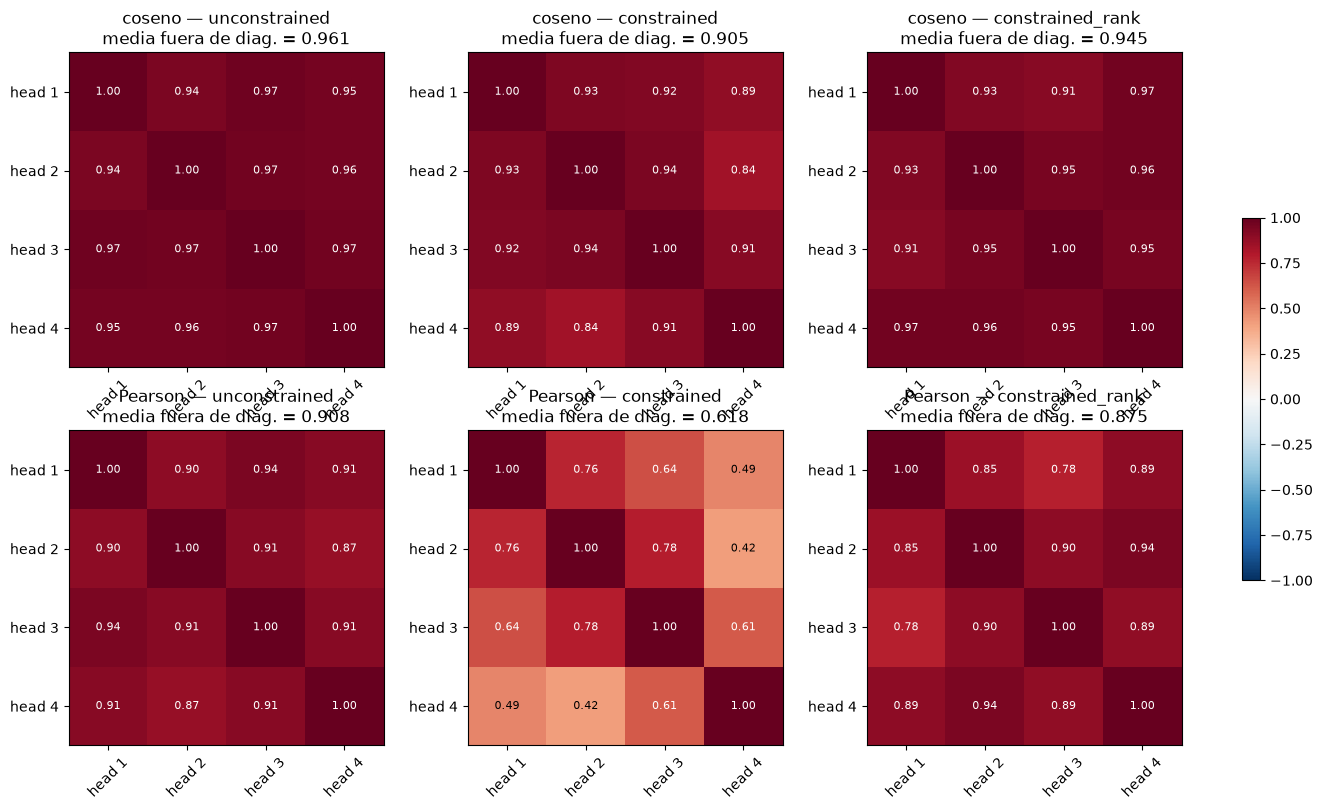

In [8]:
fig, axes = plt.subplots(2, len(MODELS), figsize=(5.2 * len(MODELS), 9))
for row, (title, mats) in enumerate([("coseno", cosine), ("Pearson", pearson)]):
    for ax, key in zip(axes[row], MODELS):
        M = mats[key]
        im = ax.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)
        ax.set_xticks(range(n_heads)); ax.set_xticklabels(head_labels, rotation=45)
        ax.set_yticks(range(n_heads)); ax.set_yticklabels(head_labels)
        for i in range(n_heads):
            for j in range(n_heads):
                ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if abs(M[i, j]) > 0.6 else "black")
        ax.set_title(f"{title} — {key}\nmedia fuera de diag. = {offdiag_mean(M):.3f}")
fig.colorbar(im, ax=axes, fraction=0.015)
save_fig(fig, "r2_head_similarity")
plt.show()

## 7. Atributos mejor predichos por cada cabeza

In [9]:
for key in MODELS:
    print(f"=== {MODELS[key]} ===")
    best = r2[key].argmax(0)
    for h in range(n_heads):
        won = [a for a in np.argsort(-r2[key][h]) if best[a] == h and r2[key][h, a] > R2_THRESHOLD]
        print(f"  {head_labels[h]} ({len(won):2d}): " + ", ".join(f"{attr_names[a]} {r2[key][h, a]:.2f}" for a in won[:12]))
    print()

=== vit-15-AwA2 ===
  head 1 ( 0): 
  head 2 ( 0): 
  head 3 ( 0): 
  head 4 ( 0): 

=== vit-15-constrained-AwA2 ===
  head 1 ( 0): 
  head 2 ( 0): 
  head 3 ( 0): 
  head 4 ( 0): 

=== vit-15-constrained_rank-AwA2 ===
  head 1 ( 0): 
  head 2 ( 0): 
  head 3 ( 0): 
  head 4 ( 0): 



## 8. Mejor cabeza por atributo — baseline vs. penalizado

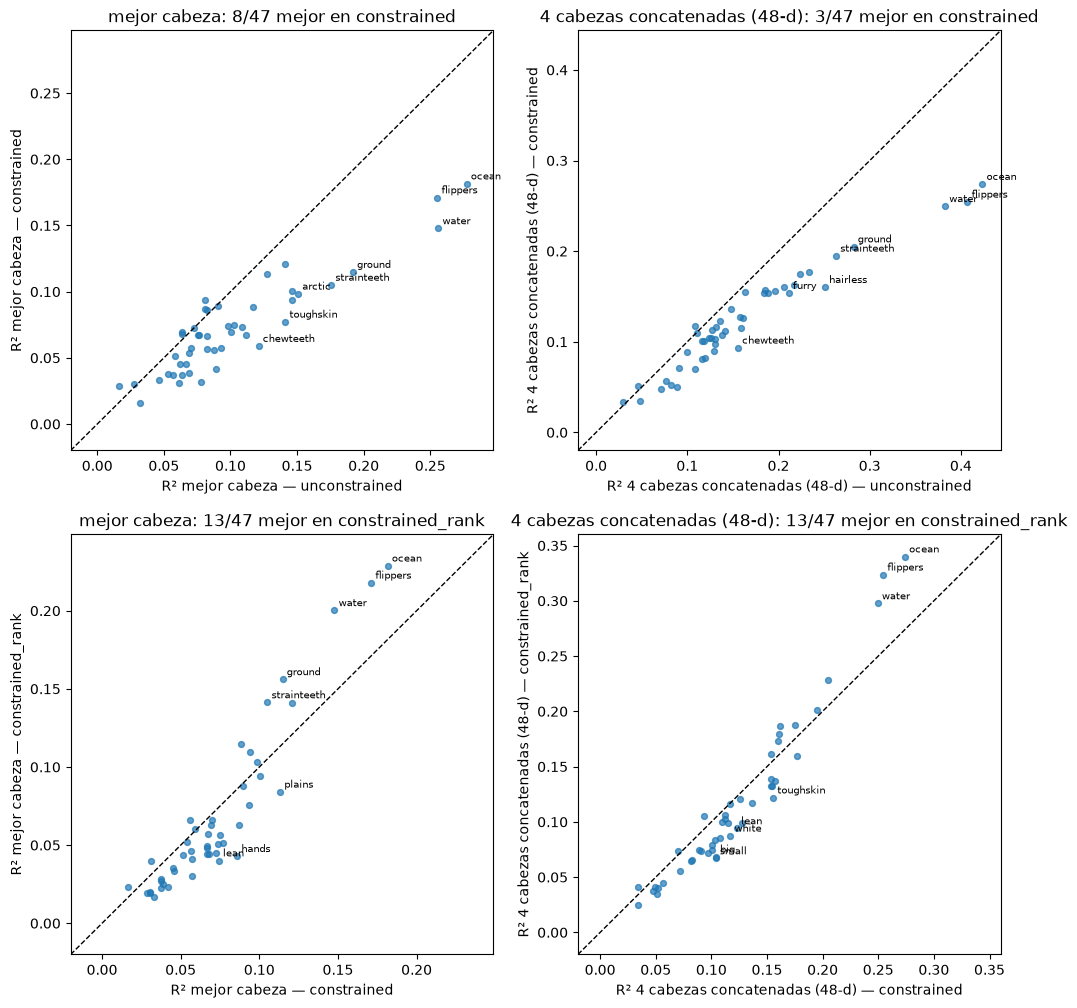

In [10]:
PAIRS = [("unconstrained", "constrained"), ("constrained", "constrained_rank")]   # (eje x, eje y)
fig, axes = plt.subplots(len(PAIRS), 2, figsize=(12, 6 * len(PAIRS)))
for r, (kx, ky) in enumerate(PAIRS):
    for ax, (title, get) in zip(axes[r], [("mejor cabeza", lambda k: r2[k].max(0)),
                                          ("4 cabezas concatenadas (48-d)", lambda k: r2_block[k])]):
        xb, yi = get(kx), get(ky)
        ax.scatter(xb, yi, s=18, alpha=0.7)
        lim = [min(xb.min(), yi.min(), 0) - 0.02, max(xb.max(), yi.max()) + 0.02]
        ax.plot(lim, lim, "k--", lw=1)
        for a in np.argsort(-np.abs(yi - xb))[:8]:
            ax.annotate(attr_names[a], (xb[a], yi[a]), fontsize=7, xytext=(3, 3), textcoords="offset points")
        ax.set_xlim(lim); ax.set_ylim(lim)
        ax.set_xlabel(f"R² {title} — {kx}"); ax.set_ylabel(f"R² {title} — {ky}")
        ax.set_title(f"{title}: {(yi > xb).sum()}/{n_attr} mejor en {ky}")
save_fig(fig, "best_head_r2_scatter")
plt.show()

## 9. Null de permutación por clase
Los atributos de AwA2 son constantes por clase, así que un R² > 0 puede significar solo "esta cabeza distingue clases". Null: permutar las filas de la matriz clase × atributo (se reasignan los atributos entre clases, preservando la estructura de correlación entre atributos) y recalcular el R² con el mismo `probe_r2` y los mismos folds. Un atributo/cabeza cuenta como señal semántica solo si supera el null.

=== vit-15-AwA2 ===
  head 1: R² medio obs 0.066 | null 0.019 [0.013, 0.028] | atributos con p<0.05: 17/47 (esperado por azar ≈ 2.4) | R² > τ y p<0.05: 0
  head 2: R² medio obs 0.095 | null 0.031 [0.023, 0.039] | atributos con p<0.05: 29/47 (esperado por azar ≈ 2.4) | R² > τ y p<0.05: 0
  head 3: R² medio obs 0.075 | null 0.023 [0.016, 0.031] | atributos con p<0.05: 28/47 (esperado por azar ≈ 2.4) | R² > τ y p<0.05: 0
  head 4: R² medio obs 0.068 | null 0.022 [0.016, 0.029] | atributos con p<0.05: 29/47 (esperado por azar ≈ 2.4) | R² > τ y p<0.05: 0

=== vit-15-constrained-AwA2 ===
  head 1: R² medio obs 0.033 | null 0.014 [0.011, 0.020] | atributos con p<0.05: 28/47 (esperado por azar ≈ 2.4) | R² > τ y p<0.05: 0
  head 2: R² medio obs 0.028 | null 0.011 [0.008, 0.015] | atributos con p<0.05: 19/47 (esperado por azar ≈ 2.4) | R² > τ y p<0.05: 0
  head 3: R² medio obs 0.066 | null 0.025 [0.018, 0.033] | atributos con p<0.05: 25/47 (esperado por azar ≈ 2.4) | R² > τ y p<0.05: 0
  head 4:

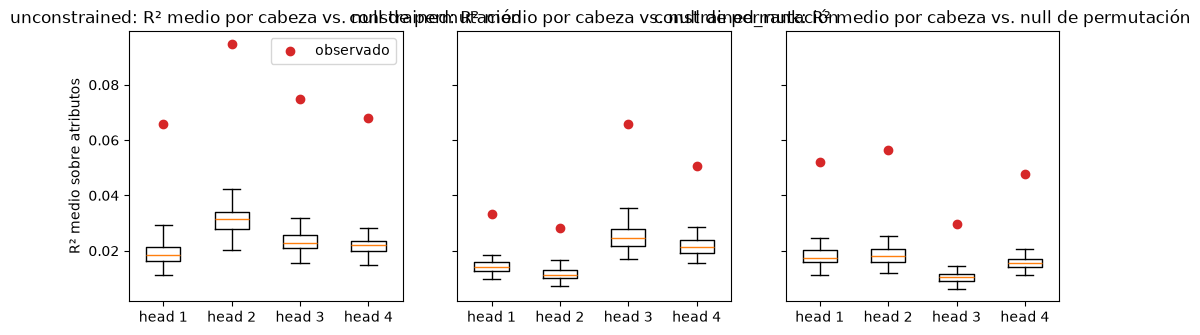

/var/folders/sx/_3f9ftxx24q3hbz_25d1xrjh0000gn/T/ipykernel_11234/2787426557.py:16: RuntimeWarning: Mean of empty slice
  return float(np.nanmean(M[iu]))


,unconstrained,constrained,constrained_rank
"[exceso sobre null, τ=0.3] cobertura (nº atributos)",0.0,0.0,0.0
"[exceso sobre null, τ=0.3] cabezas por atributo cubierto",NaN,NaN,NaN
"[exceso sobre null, τ=0.3] Jaccard medio entre cabezas",NaN,NaN,NaN
"[exceso sobre null, τ=0.3] entropía normalizada entre cabezas",NaN,NaN,NaN
"[exceso sobre null, τ=0.3] nº atributos > τ, head 1",0.0,0.0,0.0
"[exceso sobre null, τ=0.3] nº atributos > τ, head 2",0.0,0.0,0.0
"[exceso sobre null, τ=0.3] nº atributos > τ, head 3",0.0,0.0,0.0
"[exceso sobre null, τ=0.3] nº atributos > τ, head 4",0.0,0.0,0.0


In [11]:
N_PERM = 100
ALPHA = 0.05

rng = np.random.default_rng(SEED)
n_cls = len(classes)
class_attr = np.zeros((n_cls, n_attr))                 # matriz clase × atributo (50 × n_attr)
class_attr[labels] = Y_cont
perms = [rng.permutation(n_cls) for _ in range(N_PERM)]

null_r2 = {k: np.zeros((N_PERM, n_heads, n_attr)) for k in MODELS}
for key, feats in head_feats.items():
    for p, perm in enumerate(perms):
        Y_perm = class_attr[perm][labels]
        for h in range(n_heads):
            null_r2[key][p, h] = probe_r2(feats[:, h], Y_perm, folds_image)
    np.save(OUTPUT_DIR / f"null_r2_permclass_{key}_{RUN_TAG}.npy", null_r2[key])

# p-valor empírico por (cabeza, atributo): P(R²_null >= R²_obs), con corrección +1
pval = {k: (1 + (null_r2[k] >= r2[k][None]).sum(0)) / (N_PERM + 1) for k in MODELS}
# z-score contra el null y R² "en exceso" sobre la media del null
excess = {k: r2[k] - null_r2[k].mean(0) for k in MODELS}

for key in MODELS:
    null_mean_head = null_r2[key].mean(2)               # (N_PERM, H)
    print(f"=== {MODELS[key]} ===")
    for h in range(n_heads):
        lo, hi = np.percentile(null_mean_head[:, h], [2.5, 97.5])
        print(f"  {head_labels[h]}: R² medio obs {r2[key][h].mean():.3f} | null {null_mean_head[:, h].mean():.3f} "
              f"[{lo:.3f}, {hi:.3f}] | atributos con p<{ALPHA}: {(pval[key][h] < ALPHA).sum()}/{n_attr} "
              f"(esperado por azar ≈ {ALPHA * n_attr:.1f}) | R² > τ y p<{ALPHA}: "
              f"{((r2[key][h] > R2_THRESHOLD) & (pval[key][h] < ALPHA)).sum()}")
    print()

fig, axes = plt.subplots(1, len(MODELS), figsize=(12, 3.5), sharey=True)
for ax, key in zip(axes, MODELS):
    ax.boxplot(null_r2[key].mean(2), positions=range(n_heads), widths=0.5, showfliers=False)
    ax.scatter(range(n_heads), r2[key].mean(1), color="C3", zorder=3, label="observado")
    ax.set_xticks(range(n_heads)); ax.set_xticklabels(head_labels)
    ax.set_title(f"{key}: R² medio por cabeza vs. null de permutación")
axes[0].set_ylabel("R² medio sobre atributos"); axes[0].legend()
save_fig(fig, "r2_vs_permutation_null")
plt.show()

# Especialización con R² en exceso sobre el null (en vez de R² crudo)
rows_null = {k: {f"[exceso sobre null, τ={R2_THRESHOLD}] {m}": v
                 for m, v in specialization_metrics(excess[k], R2_THRESHOLD).items()} for k in MODELS}
pd.DataFrame(rows_null).round(3)

## 10. Probing sobre el residual
Mismo probe, mismos atributos y mismos folds, pero sobre el **residual stream** (48-d) en vez de la salida de una cabeza (12-d). Se captura en el mismo token (`TOKEN`) a lo largo de toda la red: salida del embedding, y en cada bloque después de sumar la atención (`mid`) y después de sumar el MLP (`post`). El `post` del último bloque es exactamente lo que recibe el clasificador.

Lectura: el residual acumula lo que escribieron todas las cabezas y MLPs anteriores, así que es el techo de lo linealmente decodificable en ese punto; la salida de una cabeza es solo lo que esa cabeza aporta. La comparación de igual dimensión contra el residual es el probe de las 4 cabezas concatenadas (48-d, `r2_block`), no el de una cabeza sola.

In [12]:
n_blocks = models["unconstrained"][1]["num_hidden_layers"]
RESID_POINTS = ["embedding"] + [f"b{b} {s}" for b in range(1, n_blocks + 1) for s in ("mid", "post")]
RESID_TAG = f"resid_{TOKEN}_visual"


@torch.no_grad()
def extract_residual(model):
    """Residual en cada punto de RESID_POINTS, reducido al token TOKEN: dict punto -> (N, hidden_size)."""
    captured = {}
    hooks = []
    for b, block in enumerate(model.encoder.blocks, start=1):
        if b == 1:   # entrada del primer bloque = salida del embedding
            hooks.append(block.register_forward_hook(lambda _m, inp, _out: captured.__setitem__("embedding", inp[0])))
        # entrada de layernorm_2 = x + attention_output (residual después de la atención)
        hooks.append(block.layernorm_2.register_forward_hook(
            lambda _m, inp, _out, b=b: captured.__setitem__(f"b{b} mid", inp[0])))
        # salida del bloque = residual después del MLP
        hooks.append(block.register_forward_hook(
            lambda _m, _inp, out, b=b: captured.__setitem__(f"b{b} post", out[0])))
    feats = {point: [] for point in RESID_POINTS}
    try:
        for images, _, _ in testloader:
            model(images.to(device))
            for point in RESID_POINTS:
                resid = captured[point]                                            # (B, T, d)
                resid = resid[:, 0] if TOKEN == "cls" else resid[:, 1:].mean(dim=1)
                feats[point].append(resid.cpu())
    finally:
        for hook in hooks:
            hook.remove()
    return {point: torch.cat(chunks).numpy() for point, chunks in feats.items()}


resid_feats = {key: extract_residual(model) for key, (model, _, _) in models.items()}

r2_resid, r2_resid_unseen = {}, {}
for key, feats in resid_feats.items():
    r2_resid[key] = np.stack([probe_r2(feats[point], Y_cont, folds_image) for point in RESID_POINTS])          # (P, n_attr)
    r2_resid_unseen[key] = np.stack([probe_r2(feats[point], Y_cont, folds_class) for point in RESID_POINTS])
    pd.DataFrame(r2_resid[key], index=RESID_POINTS, columns=attr_names).to_csv(OUTPUT_DIR / f"r2_{key}_{RESID_TAG}.csv")
    pd.DataFrame(r2_resid_unseen[key], index=RESID_POINTS, columns=attr_names).to_csv(
        OUTPUT_DIR / f"r2_unseen_classes_{key}_{RESID_TAG}.csv")

# Tabla: R² medio sobre atributos por punto del residual, con las cabezas del bloque BLOCK_IDX como referencia.
heads_concat = f"cabezas b{BLOCK_IDX} concatenadas (48-d)"
heads_best = f"mejor cabeza b{BLOCK_IDX} por atributo (12-d)"
resid_summary = pd.DataFrame({
    (key, col): pd.Series({
        **dict(zip(RESID_POINTS, scores[key].mean(1))),
        heads_concat: (r2_block if col == "R² medio" else r2_block_unseen)[key].mean(),
        heads_best: per_head[key].max(0).mean(),
    })
    for key in MODELS
    for col, scores, per_head in [("R² medio", r2_resid, r2), ("R² medio, clases no vistas", r2_resid_unseen, r2_unseen)]
})
resid_summary[("Δ (interp. − baseline)", "R² medio")] = (
    resid_summary[("constrained", "R² medio")] - resid_summary[("unconstrained", "R² medio")])
resid_summary.to_csv(OUTPUT_DIR / f"summary_{RESID_TAG}.csv")
resid_summary.round(3)

unconstrained                             \
                                         R² medio R² medio, clases no vistas   
embedding                                  -0.000                     -0.048   
b1 mid                                      0.149                      0.004   
b1 post                                     0.150                      0.003   
b2 mid                                      0.173                      0.007   
b2 post                                     0.173                      0.007   
b3 mid                                      0.192                      0.011   
b3 post                                     0.192                      0.011   
b4 mid                                      0.211                      0.020   
b4 post                                     0.214                      0.021   
cabezas b4 concatenadas (48-d)              0.161                      0.007   
mejor cabeza b4 por atributo (12-d)         0.100                     -0.000   

                                    constrained                             \
                                       R² medio R² medio, clases no vistas   
embedding                                -0.000                     -0.048   
b1 mid                                    0.149                      0.008   
b1 post                                   0.150                      0.010   
b2 mid                                    0.172                      0.014   
b2 post                                   0.172                      0.013   
b3 mid                                    0.193                      0.014   
b3 post                                   0.194                      0.014   
b4 mid                                    0.205                      0.017   
b4 post                                   0.209                      0.017   
cabezas b4 concatenadas (48-d)            0.123                     -0.035   
mejor cabeza b4 por atributo (12-d)       0.072                     -0.023   

                                    constrained_rank  \
                                            R² medio   
embedding                                     -0.000   
b1 mid                                         0.146   
b1 post                                        0.146   
b2 mid                                         0.173   
b2 post                                        0.173   
b3 mid                                         0.202   
b3 post                                        0.202   
b4 mid                                         0.208   
b4 post                                        0.212   
cabezas b4 concatenadas (48-d)                 0.116   
mejor cabeza b4 por atributo (12-d)            0.067   

                                                                \
                                    R² medio, clases no vistas   
embedding                                               -0.048   
b1 mid                                                   0.006   
b1 post                                                  0.006   
b2 mid                                                   0.011   
b2 post                                                  0.011   
b3 mid                                                   0.019   
b3 post                                                  0.019   
b4 mid                                                   0.020   
b4 post                                                  0.021   
cabezas b4 concatenadas (48-d)                          -0.022   
mejor cabeza b4 por atributo (12-d)                     -0.019   

                                    Δ (interp. − baseline)  
                                                  R² medio  
embedding                                            0.000  
b1 mid                                               0.001  
b1 post                                              0.000  
b2 mid                                              -0.001  
b2 post                   

### R² a lo largo del residual

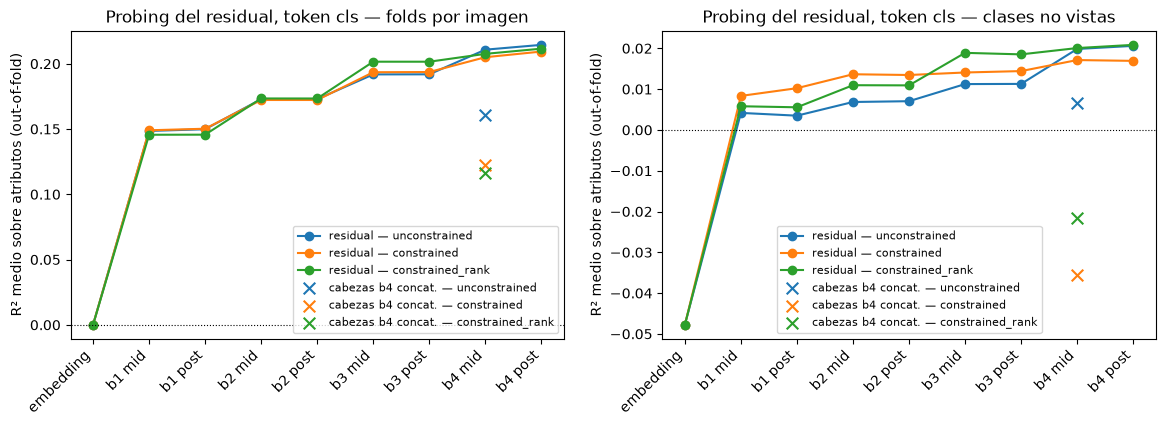

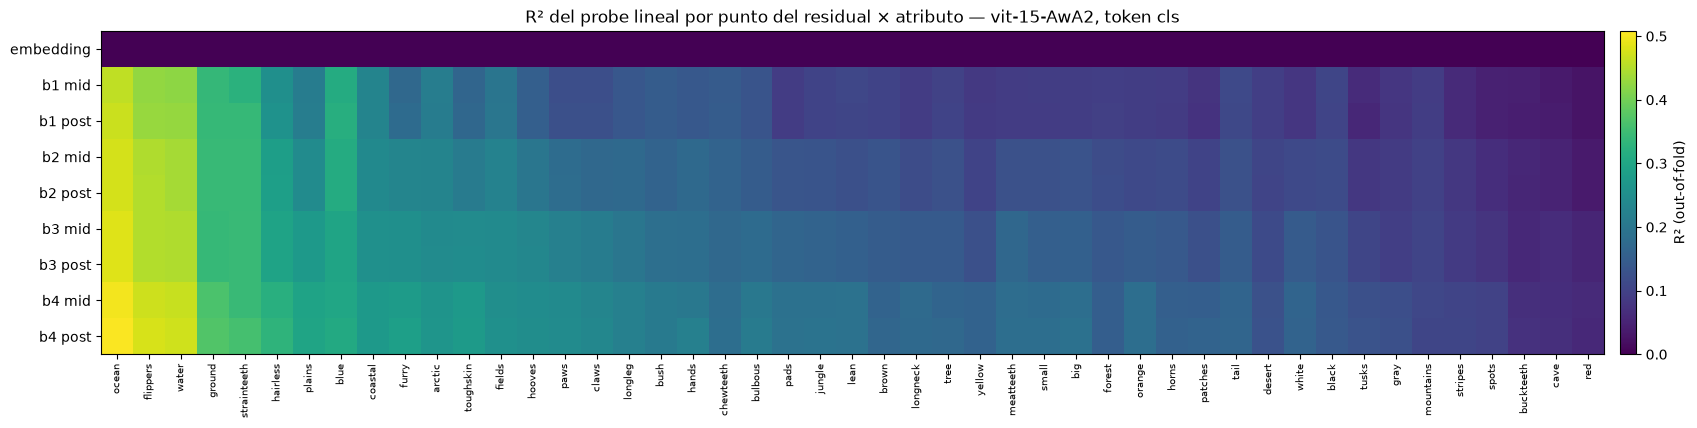

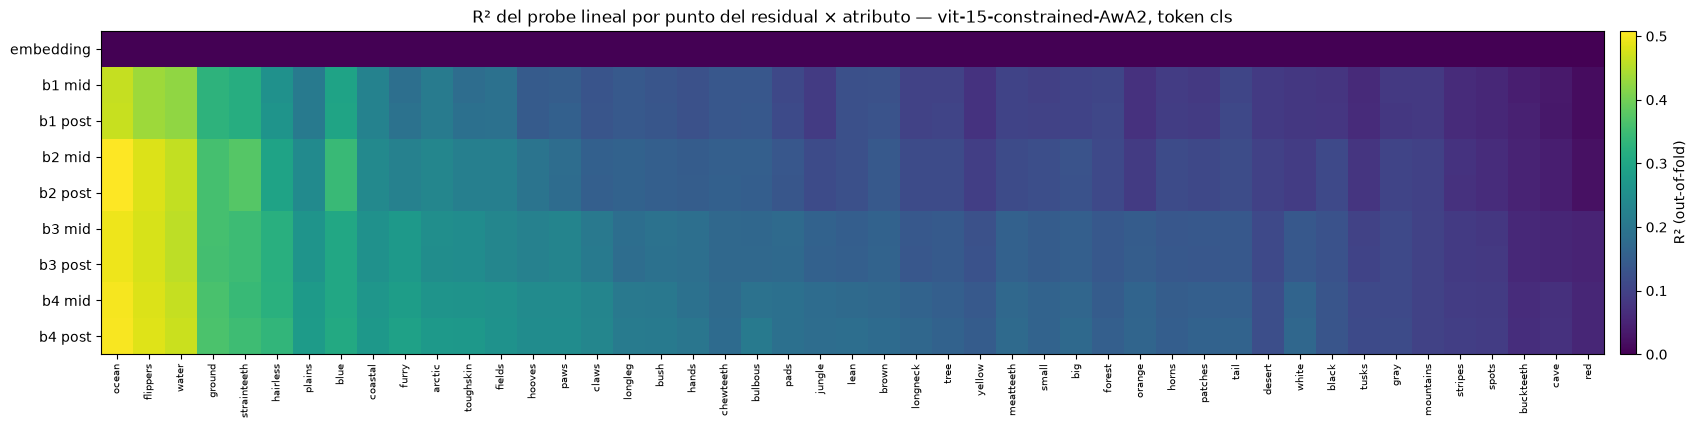

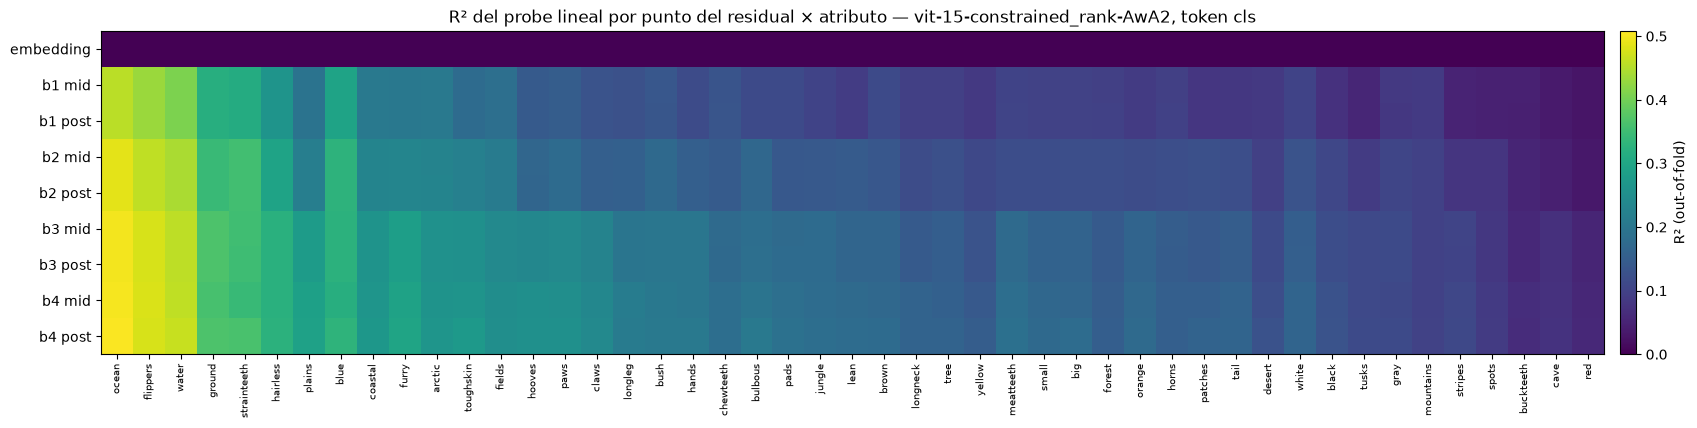

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(RESID_POINTS))
COLORS = [f"C{i}" for i in range(len(MODELS))]
x_heads = RESID_POINTS.index(f"b{BLOCK_IDX} mid")   # punto del residual donde escriben las cabezas probadas arriba
for ax, (title, scores) in zip(axes, [("folds por imagen", r2_resid), ("clases no vistas", r2_resid_unseen)]):
    for color, key in zip(COLORS, MODELS):
        ax.plot(x, scores[key].mean(1), marker="o", color=color, label=f"residual — {key}")
    block_scores = r2_block if scores is r2_resid else r2_block_unseen
    for color, key in zip(COLORS, MODELS):
        ax.scatter(x_heads, block_scores[key].mean(), marker="x", s=70, color=color, zorder=3,
                   label=f"cabezas b{BLOCK_IDX} concat. — {key}")
    ax.axhline(0, color="k", lw=0.8, ls=":")
    ax.set_xticks(x); ax.set_xticklabels(RESID_POINTS, rotation=45, ha="right")
    ax.set_ylabel("R² medio sobre atributos (out-of-fold)")
    ax.set_title(f"Probing del residual, token {TOKEN} — {title}")
    ax.legend(fontsize=8)
fig.savefig(OUTPUT_DIR / f"r2_residual_depth_{RESID_TAG}.png", dpi=150, bbox_inches="tight")
plt.show()

vmax_resid = max(r2_resid[k].max() for k in MODELS)
for key in MODELS:
    fig, ax = plt.subplots(figsize=(20, 4.2))
    im = ax.imshow(np.clip(r2_resid[key][:, attr_order], 0, None), cmap="viridis", vmin=0, vmax=vmax_resid, aspect="auto")
    ax.set_yticks(x); ax.set_yticklabels(RESID_POINTS)
    ax.set_xticks(range(n_attr)); ax.set_xticklabels([attr_names[i] for i in attr_order], rotation=90, fontsize=7)
    ax.set_title(f"R² del probe lineal por punto del residual × atributo — {MODELS[key]}, token {TOKEN}")
    fig.colorbar(im, ax=ax, label="R² (out-of-fold)", fraction=0.02, pad=0.01)
    fig.savefig(OUTPUT_DIR / f"r2_heatmap_{key}_{RESID_TAG}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 11. Selectividad (Hewitt & Liang, 2019)

Un R² alto no distingue "la cabeza codifica el atributo" de "el probe tiene capacidad para memorizar". La **selectividad** compara contra una *tarea de control*:

$$\text{Selectividad} = R^2_{\text{tarea real}} - R^2_{\text{control}}$$

La tarea de control sigue la receta del paper: el "tipo de dato" es la clase (los atributos de AwA2 son constantes por clase) y a cada clase se le asigna al azar el vector de atributos de *otra* clase, fijo para todas sus imágenes. Se preserva la distribución marginal de cada atributo y la estructura de correlación entre atributos, pero se destruye la relación con lo que se ve en la imagen. Un probe que igual lo aprende solo está memorizando la identidad de la clase.

Se reutilizan las `N_PERM` tareas de control de la sección 9 (`null_r2`, mismo `probe_r2`, mismos folds) y se promedian. Esto es lo que antes se llamó R² "en exceso" sobre el null, ahora con la lectura de selectividad y resumido por cabeza. Como referencia de capacidad, se agrega el probe sobre las 4 cabezas concatenadas (48-d): más dimensiones → más capacidad de memorización → menor selectividad esperada para un mismo R².

In [14]:
# Referencia de capacidad: control sobre las 4 cabezas concatenadas (48-d), mismas permutaciones que null_r2
null_block = {k: np.zeros((N_PERM, n_attr)) for k in MODELS}
for key, feats in head_feats.items():
    X_block = feats.reshape(len(feats), -1)
    for p, perm in enumerate(perms):
        null_block[key][p] = probe_r2(X_block, class_attr[perm][labels], folds_image)

selectivity = {k: r2[k] - null_r2[k].mean(0) for k in MODELS}             # (H, n_attr)
selectivity_block = {k: r2_block[k] - null_block[k].mean(0) for k in MODELS}  # (n_attr,)

rows = []
for key in MODELS:
    # selectividad media por permutación -> IC 95% del control (incertidumbre de la tarea de control)
    for h in range(n_heads + 1):
        if h < n_heads:
            real, ctrl = r2[key][h].mean(), null_r2[key][:, h].mean(1)           # ctrl: (N_PERM,)
            name = head_labels[h]
            frac_sig = float((pval[key][h] < ALPHA).mean())
        else:
            real, ctrl = r2_block[key].mean(), null_block[key].mean(1)
            name = "4 cabezas concat. (48-d)"
            frac_sig = np.nan
        sel_p = real - ctrl
        lo, hi = np.percentile(sel_p, [2.5, 97.5])
        rows.append({"modelo": key, "probe": name, "R² real": real, "R² control": ctrl.mean(),
                     "selectividad": sel_p.mean(), "IC95 inf": lo, "IC95 sup": hi,
                     "selectividad / R² real": sel_p.mean() / real if real > 0 else np.nan,
                     f"frac. atributos p<{ALPHA}": frac_sig})
selectivity_table = pd.DataFrame(rows).set_index(["modelo", "probe"])
selectivity_table.to_csv(OUTPUT_DIR / f"selectivity_{RUN_TAG}.csv")
for key in MODELS:
    pd.DataFrame(selectivity[key], index=head_labels, columns=attr_names).to_csv(
        OUTPUT_DIR / f"selectivity_{key}_{RUN_TAG}.csv")
selectivity_table.round(3)

R² real  R² control  selectividad  \
modelo           probe                                                         
unconstrained    head 1                      0.066       0.019         0.047   
                 head 2                      0.095       0.031         0.064   
                 head 3                      0.075       0.023         0.052   
                 head 4                      0.068       0.022         0.046   
                 4 cabezas concat. (48-d)    0.161       0.057         0.103   
constrained      head 1                      0.033       0.014         0.019   
                 head 2                      0.028       0.011         0.017   
                 head 3                      0.066       0.025         0.041   
                 head 4                      0.051       0.021         0.029   
                 4 cabezas concat. (48-d)    0.123       0.049         0.074   
constrained_rank head 1                      0.052       0.018         0.034   
                 head 2                      0.056       0.018         0.038   
                 head 3                      0.030       0.011         0.019   
                 head 4                      0.048       0.016         0.032   
                 4 cabezas concat. (48-d)    0.116       0.043         0.073   

                                           IC95 inf  IC95 sup  \
modelo           probe                                          
unconstrained    head 1                       0.037     0.053   
                 head 2                       0.055     0.072   
                 head 3                       0.044     0.059   
                 head 4                       0.039     0.052   
                 4 cabezas concat. (48-d)     0.091     0.117   
constrained      head 1                       0.014     0.022   
                 head 2                       0.013     0.020   
                 head 3                       0.033     0.048   
                 head 4                       0.024     0.035   
                 4 cabezas concat. (48-d)     0.064     0.084   
constrained_rank head 1                       0.028     0.040   
                 head 2                       0.032     0.044   
                 head 3                       0.014     0.023   
                 head 4                       0.027     0.036   
                 4 cabezas concat. (48-d)     0.063     0.083   

                                           selectividad / R² real  \
modelo           probe                                              
unconstrained    head 1                                     0.708   
                 head 2                                     0.670   
                 head 3                                     0.689   
                 head 4                                     0.677   
                 4 cabezas concat. (48-d)                   0.642   
constrained      head 1                                     0.566   
                 head 2                                     0.593   
                 head 3                                     0.622   
                 head 4                                     0.578   
                 4 cabezas concat. (48-d)                   0.600   
constrained_rank head 1                                     0.655   
                 head 2                                     0.676   
                 head 3                                     0.645   
                 head 4                                     0.671   
                 4 cabezas concat. (48-d)                   0.633   

                                           frac. atributos p<0.05  
modelo           probe                                             
unconstrained    head 1                                     0.362  
                 head 2                                     0.617  
                 head 3                                     0.596  
                 head 4                                     0.

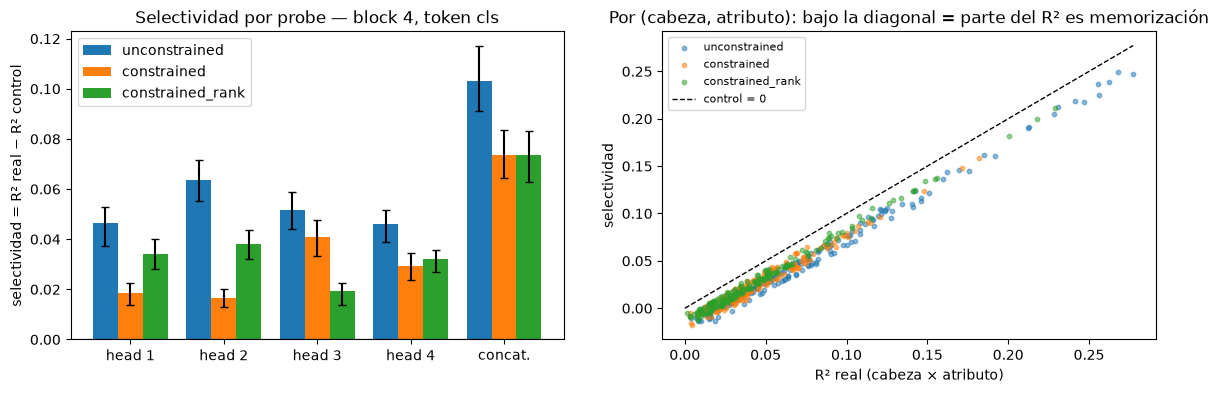

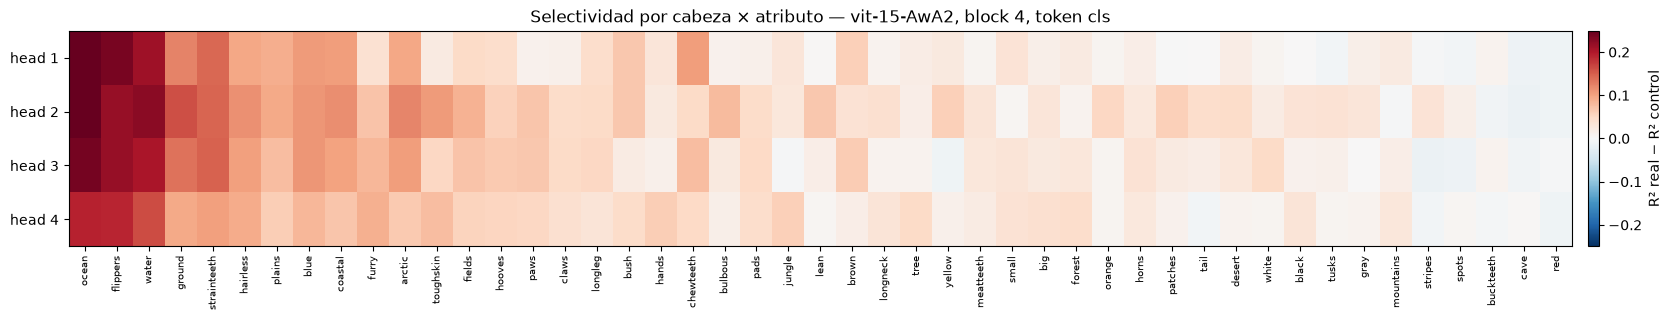

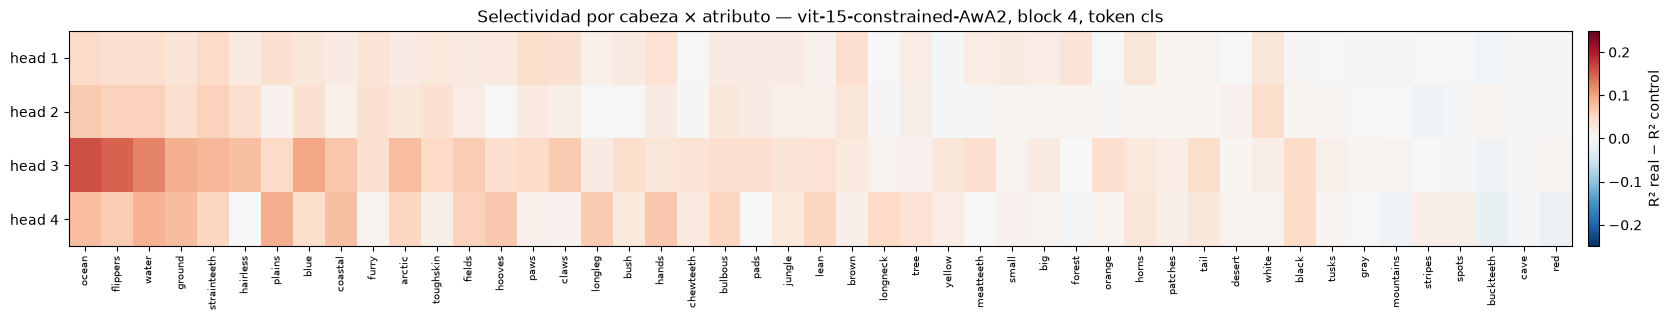

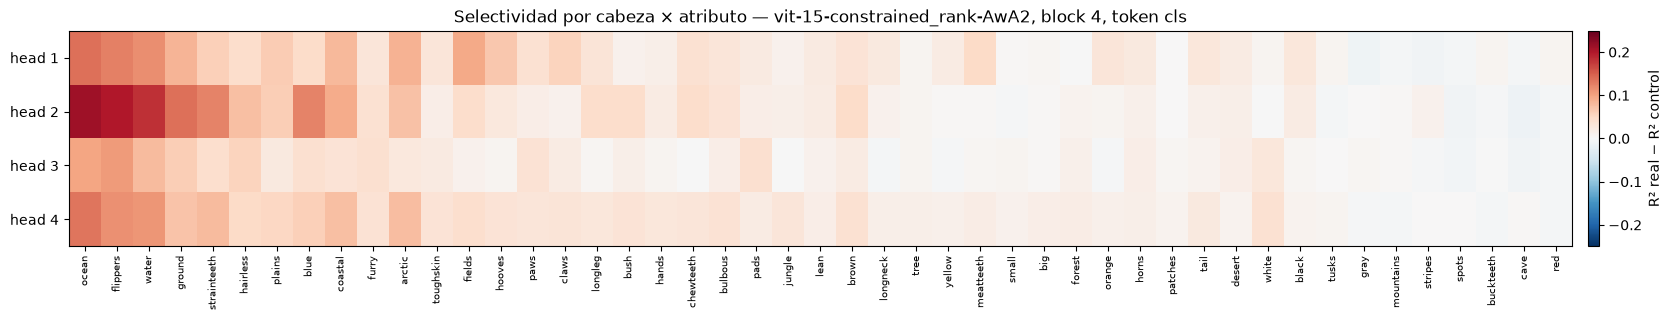

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
labels_probe = head_labels + ["concat."]
x = np.arange(len(labels_probe))
w = 0.8 / len(MODELS)
for i, key in enumerate(MODELS):
    t = selectivity_table.loc[key]
    err = np.stack([t["selectividad"] - t["IC95 inf"], t["IC95 sup"] - t["selectividad"]])
    axes[0].bar(x + (i - (len(MODELS) - 1) / 2) * w, t["selectividad"], width=w, yerr=err, capsize=3, label=key)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_xticks(x); axes[0].set_xticklabels(labels_probe)
axes[0].set_ylabel("selectividad = R² real − R² control")
axes[0].set_title(f"Selectividad por probe — block {BLOCK_IDX}, token {TOKEN}")
axes[0].legend()

for key, color in zip(MODELS, [f"C{i}" for i in range(len(MODELS))]):
    axes[1].scatter(r2[key].ravel(), selectivity[key].ravel(), s=10, alpha=0.5, color=color, label=key)
lim = [0, max(r2[k].max() for k in MODELS)]
axes[1].plot(lim, lim, "k--", lw=1, label="control = 0")
axes[1].set_xlabel("R² real (cabeza × atributo)"); axes[1].set_ylabel("selectividad")
axes[1].set_title("Por (cabeza, atributo): bajo la diagonal = parte del R² es memorización")
axes[1].legend(fontsize=8)
save_fig(fig, "selectivity")
plt.show()

vmax_sel = max(selectivity[k].max() for k in MODELS)
for key in MODELS:
    fig, ax = plt.subplots(figsize=(20, 2.8))
    im = ax.imshow(selectivity[key][:, attr_order], cmap="RdBu_r", vmin=-vmax_sel, vmax=vmax_sel, aspect="auto")
    ax.set_yticks(range(n_heads)); ax.set_yticklabels(head_labels)
    ax.set_xticks(range(n_attr)); ax.set_xticklabels([attr_names[i] for i in attr_order], rotation=90, fontsize=7)
    ax.set_title(f"Selectividad por cabeza × atributo — {MODELS[key]}, block {BLOCK_IDX}, token {TOKEN}")
    fig.colorbar(im, ax=ax, label="R² real − R² control", fraction=0.02, pad=0.01)
    save_fig(fig, f"selectivity_heatmap_{key}")
    plt.show()